# Cookie Cats A/B Testi - 2. Keşifsel Analiz

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
colors = {"gate_30": "tab:blue", "gate_40": "tab:orange"}

İlk notebook'ta bulduğum veri hatasını (49.854 round) çıkarıp temiz veriyi kaydediyorum.

In [2]:
df = pd.read_csv("../data/cookie_cats.csv")
df = df[df["sum_gamerounds"] < 40000]
print(len(df))
df.to_csv("../data/cookie_cats_clean.csv", index=False)

90188


## Round dağılımı

In [3]:
df.groupby("version")["sum_gamerounds"].describe()

,count,mean,std,min,25%,50%,75%,max
version,,,,,,,,
gate_30,44699.0,51.342111,102.057598,0.0,5.0,17.0,50.0,2961.0
gate_40,45489.0,51.298776,103.294416,0.0,5.0,16.0,52.0,2640.0


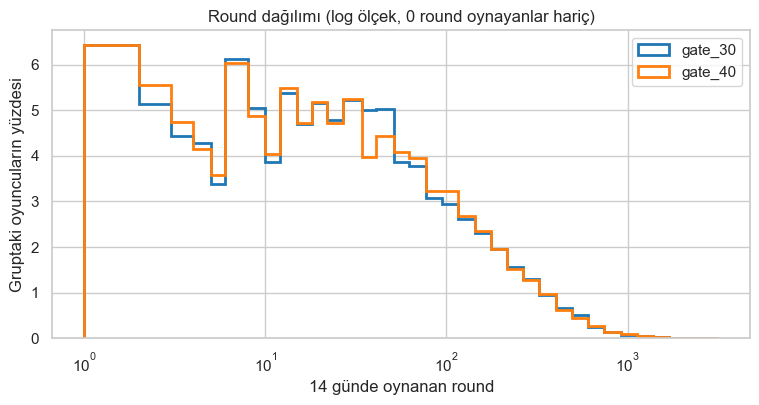

In [4]:
bins = np.unique(np.round(np.logspace(0, 3.5, 40)))   # log aralıklı tam sayı sınırları
plt.figure(figsize=(9, 4))
for v in ["gate_30", "gate_40"]:
    x = df.loc[(df["version"] == v) & (df["sum_gamerounds"] > 0), "sum_gamerounds"]
    plt.hist(x, bins=bins, weights=np.ones(len(x)) / len(x) * 100, histtype="step", linewidth=2, label=v, color=colors[v])
plt.xscale("log")
plt.legend()
plt.title("Round dağılımı (log ölçek, 0 round oynayanlar hariç)")
plt.xlabel("14 günde oynanan round")
plt.ylabel("Gruptaki oyuncuların yüzdesi")
plt.savefig("../figures/01_round_dagilimi.png", dpi=120, bbox_inches="tight")
plt.show()

Dağılım çok sağa çarpık. Medyan 16-17 round iken ortalama 51 civarında, çünkü az sayıda oyuncu çok fazla oynuyor ve ortalamayı yukarı çekiyor. Bu yüzden round karşılaştırmasında ortalama yerine medyana bakacağım. İki grubun dağılımı birbirine çok benziyor.

## Gruplara göre retention

In [5]:
ret = df.groupby("version")[["retention_1", "retention_7"]].mean()
ret

,retention_1,retention_7
version,,
gate_30,0.448198,0.190183
gate_40,0.442283,0.182000


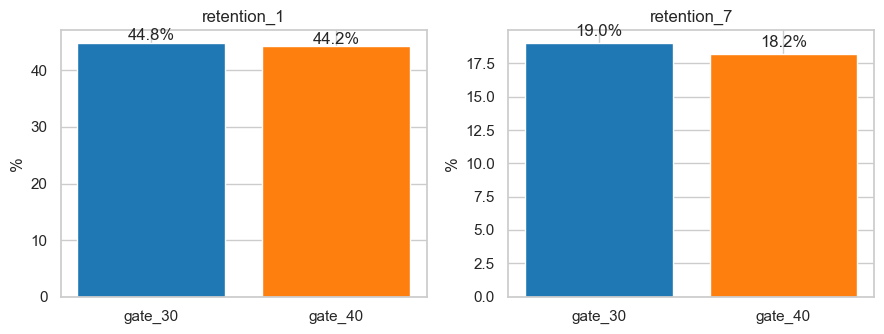

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
for ax, col in zip(axes, ["retention_1", "retention_7"]):
    ax.bar(ret.index, ret[col] * 100, color=[colors["gate_30"], colors["gate_40"]])
    for i, v in enumerate(ret[col] * 100):
        ax.text(i, v + 0.5, f"{v:.1f}%", ha="center")
    ax.set_title(col)
    ax.set_ylabel("%")
plt.tight_layout()
plt.savefig("../figures/02_retention_gruplar.png", dpi=120, bbox_inches="tight")
plt.show()

In [7]:
diff7 = ret.loc["gate_40", "retention_7"] - ret.loc["gate_30", "retention_7"]
print(f"retention_7 farkı: {diff7*100:.2f} puan")
print(f"Göreli fark: {diff7 / ret.loc['gate_30', 'retention_7'] * 100:.1f}%")

retention_7 farkı: -0.82 puan
Göreli fark: -4.3%


gate_40 her iki metrikte de biraz daha düşük. retention_7'deki 0.82 puanlık fark küçük görünse de göreli olarak yaklaşık %4.3'lük bir düşüş. Bunun şans eseri olup olmadığını 3. notebook'ta test ediyorum.

## Oyuncular hangi round'da kalıyor?

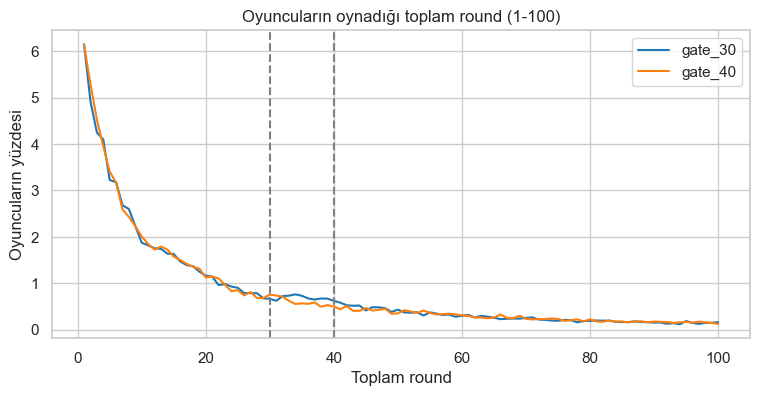

In [8]:
plt.figure(figsize=(9, 4))
for v in ["gate_30", "gate_40"]:
    sub = df[df["version"] == v]
    share = sub["sum_gamerounds"].value_counts(normalize=True).sort_index()
    share = share[(share.index >= 1) & (share.index <= 100)]
    plt.plot(share.index, share.values * 100, label=v, color=colors[v])
plt.axvline(30, color="gray", linestyle="--")
plt.axvline(40, color="gray", linestyle="--")
plt.title("Oyuncuların oynadığı toplam round (1-100)")
plt.xlabel("Toplam round")
plt.ylabel("Oyuncuların yüzdesi")
plt.legend()
plt.savefig("../figures/03_round_yigilma.png", dpi=120, bbox_inches="tight")
plt.show()

gate_30 grubunda 30-45 round civarında biraz daha fazla oyuncu var, bunlar muhtemelen kapıya takılıp kalan oyuncular. Not: kapı level'a göre konuyor ama veride sadece round sayısı var. Bir level geçilemezse tekrar oynanıyor ve bu da round sayılıyor, yani level her zaman round sayısından küçük ya da eşit. Bu yüzden yığılma tam 30'da değil biraz sonrasında.

In [9]:
print("30+ round oynayan:", round((df["sum_gamerounds"] >= 30).mean() * 100, 1), "%")
print("40+ round oynayan:", round((df["sum_gamerounds"] >= 40).mean() * 100, 1), "%")

30+ round oynayan: 36.9 %
40+ round oynayan: 30.4 %


Oyuncuların büyük kısmı kapıya hiç ulaşmıyor (en fazla %37'si 30 round'a gelmiş).

In [10]:
df["round_grubu"] = pd.cut(df["sum_gamerounds"], [-1, 0, 29, 39, 120, np.inf],
                          labels=["0", "1-29", "30-39", "40-120", "120+"])
df.pivot_table(index="round_grubu", columns="version", values="retention_7",
               aggfunc=["count", "mean"], observed=True).round(3)

count            mean        
version     gate_30 gate_40 gate_30 gate_40
round_grubu                                
0              1937    2057   0.008   0.006
1-29          26107   26819   0.045   0.042
30-39          3090    2786   0.157   0.157
40-120         8504    8712   0.353   0.328
120+           5061    5115   0.755   0.752

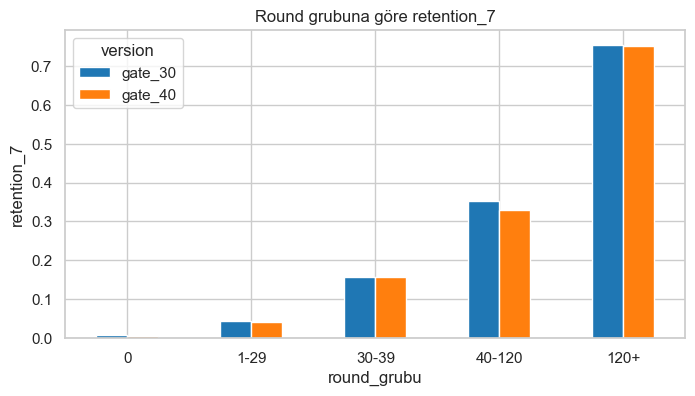

In [11]:
tbl = df.pivot_table(index="round_grubu", columns="version", values="retention_7", aggfunc="mean", observed=True)
tbl.plot(kind="bar", figsize=(8, 4), color=[colors["gate_30"], colors["gate_40"]], rot=0)
plt.title("Round grubuna göre retention_7")
plt.ylabel("retention_7")
plt.savefig("../figures/04_aralik_retention.png", dpi=120, bbox_inches="tight")
plt.show()

Fark en çok 40-120 round grubunda görünüyor. Ama bu tabloyu dikkatli yorumlamak gerekiyor: round grupları deneyden etkilenen bir değişkene göre oluştu. gate_30'da 40+ round oynayan biri kapıyı zaten geçmiş, gate_40'ta aynı gruptaki bazı oyuncular ise kapıya yeni gelmiş. Yani iki gruptaki oyuncular aynı türde değil. Bu yüzden bu tabloyu sadece fikir edinmek için kullanıyorum, asıl sonucu tüm grupları karşılaştırarak çıkaracağım.

**Özet:**
- Round dağılımı çok çarpık, medyan kullanılmalı.
- gate_40'ın retention değerleri daha düşük (retention_7'de -0.82 puan).
- Oyuncuların çoğu kapıya ulaşmıyor.
- 3. notebook'ta retention_7, retention_1 ve round sayısı için test yapacağım.